# Phân tích các yếu tố ảnh hưởng đến rating người dùng trên MovieLens bằng cách kết hợp dữ liệu thông tin phim (TMDb)

In [203]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


## Chuẩn bị Dữ liệu (Data Preparation)

In [204]:
# --- 1. ĐỌC BỘ DỮ LIỆU MOVIELENS 1M ---
# Định nghĩa tên cột cho các file .dat
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

# Đọc file users.dat
users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')

# Đọc file movies.dat
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')

# Đọc file ratings.dat
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

print("--- Đã tải xong MovieLens 1M ---")
print(f"Users shape: {users.shape}")
print(f"Movies shape: {movies.shape}")
print(f"Ratings shape: {ratings.shape}")
print("-" * 30)

--- Đã tải xong MovieLens 1M ---
Users shape: (6040, 5)
Movies shape: (3883, 3)
Ratings shape: (1000209, 4)
------------------------------


In [205]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


In [206]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB


In [207]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


In [208]:
# --- 2. ĐỌC VÀ GHÉP NỐI NỘI BỘ DỮ LIỆU TMDB ---
try:
    tmdb_credits = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except UnicodeDecodeError:
    tmdb_credits = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_movies = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

print("--- Đã tải xong TMDB 5000 Credits ---")
print(f"TMDB Credits shape: {tmdb_credits.shape}")
print(f"Các cột trong TMDB: {list(tmdb_credits.columns)}")
print("--- Đã tải xong TMDB 5000 Movies ---")
print(f"TMDB Movies shape: {tmdb_movies.shape}")
print(f"Các cột trong TMDB Movies: {list(tmdb_movies.columns)}")

--- Đã tải xong TMDB 5000 Credits ---
TMDB Credits shape: (4803, 4)
Các cột trong TMDB: ['movie_id', 'title', 'cast', 'crew']
--- Đã tải xong TMDB 5000 Movies ---
TMDB Movies shape: (4803, 20)
Các cột trong TMDB Movies: ['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']


In [209]:
# Chúng ta đổi tên cột trong file credits để khớp nhau trước khi merge
tmdb_credits.columns = ['movie_id', 'tittle_credits', 'cast', 'crew']
tmdb_movies = tmdb_movies.rename(columns={'id': 'movie_id'})

# Ghép nội bộ 2 file TMDB dựa trên 'movie_id'
tmdb_full = pd.merge(tmdb_movies, tmdb_credits, on='movie_id')

print("--- Đã ghép nội bộ TMDB ---")
print(f"Kích thước TMDB sau khi gộp: {tmdb_full.shape}")
# Bạn sẽ thấy có thêm cột budget, revenue, popularity, runtime...

--- Đã ghép nội bộ TMDB ---
Kích thước TMDB sau khi gộp: (4803, 23)


In [210]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [211]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)

print("\n--- Sample Movies ---")
movies.head(3)

print("\n--- Sample Ratings ---")
ratings.head(3)

print("\n--- Sample TMDB Credits ---")
tmdb_credits.head(3)

print("\n--- Sample TMDB Movies ---")
tmdb_movies.head(3)


--- Sample Users ---

--- Sample Movies ---

--- Sample Ratings ---

--- Sample TMDB Credits ---

--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


## Tiền xử lý dữ liệu (Data Preprocessing)

### Chuẩn hóa (Data Normalization)

In [212]:
# --- CHUẨN HÓA TÊN PHIM ĐỂ NỐI VỚI MOVIELENS ---

def clean_movielens_title(text):
    text = str(text)
    # Bỏ năm (YYYY) ở cuối
    text = re.sub(r'\s*\(\d{4}\)$', '', text) 
    return text.lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

# Tạo khóa nối 'title_join'
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# --- 4. MERGE CUỐI CÙNG (MOVIELENS + TMDB FULL) ---
movies_merged = pd.merge(movies, tmdb_full, on='title_join', how='inner')

print("-" * 30)
print(f"Số lượng phim MovieLens gốc: {movies.shape[0]}")
print(f"Số lượng phim khớp được với TMDB: {movies_merged.shape[0]}")
print("-" * 30)

# Xem các cột mới có giá trị gì
print("Danh sách các cột hiện có trong bảng movies_merged:")
print(list(movies_merged.columns))


------------------------------
Số lượng phim MovieLens gốc: 3883
Số lượng phim khớp được với TMDB: 892
------------------------------
Danh sách các cột hiện có trong bảng movies_merged:
['MovieID', 'Title', 'Genres', 'title_join', 'budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_credits', 'cast', 'crew']


### Trích xuất đặc trưng (Feature Selection)

In [213]:
# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def get_director(text):
    try:
        crew_data = ast.literal_eval(text)
        for crew_member in crew_data:
            if crew_member['job'] == 'Director':
                return crew_member['name']
        return None
    except (ValueError, SyntaxError):
        return None

def get_top_actors(text):
    try:
        cast_data = ast.literal_eval(text)
        return [member['name'] for member in cast_data[:3]]
    except (ValueError, SyntaxError):
        return []

# --- 2. ÁP DỤNG VÀO DATAFRAME ---
print("Đang trích xuất dữ liệu Đạo diễn và Diễn viên...")

# BƯỚC QUAN TRỌNG: Xóa các cột cũ nếu đã tồn tại để tránh bị trùng lặp khi chạy lại code
cols_to_reset = ['director', 'actor_1', 'actor_2', 'actor_3', 'actors_list']
movies_merged = movies_merged.drop(columns=[c for c in cols_to_reset if c in movies_merged.columns], errors='ignore')

# 1. Trích xuất Đạo diễn
movies_merged['director'] = movies_merged['crew'].apply(get_director)

# 2. Trích xuất List Diễn viên tạm thời
movies_merged['actors_list'] = movies_merged['cast'].apply(get_top_actors)

# 3. Tách List thành 3 cột riêng biệt
# apply(pd.Series) sẽ biến list [A, B, C] thành 3 cột 0, 1, 2
actors_df = movies_merged['actors_list'].apply(pd.Series)

# Đảm bảo luôn có đủ 3 cột (xử lý trường hợp dữ liệu ít diễn viên)
for i in range(3):
    if i not in actors_df.columns:
        actors_df[i] = None

# Đổi tên cột chuẩn xác
actors_df = actors_df.rename(columns={0: 'actor_1', 1: 'actor_2', 2: 'actor_3'})

# 4. Ghép vào bảng chính
# Chỉ lấy 3 cột đầu tiên (đề phòng trường hợp hiếm hoi có cột thừa)
movies_merged = pd.concat([movies_merged, actors_df[['actor_1', 'actor_2', 'actor_3']]], axis=1)

# 5. Dọn dẹp: Xóa cột list tạm và các cột json gốc cho nhẹ máy
# (Tùy chọn: Bạn có thể giữ lại cast/crew nếu muốn, nhưng ở đây tôi xóa cho gọn như yêu cầu trước)
movies_merged = movies_merged.drop(columns=['actors_list'], errors='ignore')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print("Các cột hiện có sau khi xử lý:")
print(list(movies_merged.columns))

print("\n5 dòng dữ liệu mẫu:")
print(movies_merged[['Title', 'director', 'actor_1', 'actor_2', 'actor_3']].head())

Đang trích xuất dữ liệu Đạo diễn và Diễn viên...


------------------------------
Các cột hiện có sau khi xử lý:
['MovieID', 'Title', 'Genres', 'title_join', 'budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_credits', 'cast', 'crew', 'director', 'actor_1', 'actor_2', 'actor_3']

5 dòng dữ liệu mẫu:
                     Title         director          actor_1         actor_2  \
0         Toy Story (1995)    John Lasseter        Tom Hanks       Tim Allen   
1         GoldenEye (1995)  Martin Campbell   Pierce Brosnan       Sean Bean   
2             Nixon (1995)     Oliver Stone  Anthony Hopkins      Joan Allen   
3  Cutthroat Island (1995)     Renny Harlin      Geena Davis  Matthew Modine   
4            Casino (1995)  Martin Scorsese   Robert De Niro    Sharon Stone   

             actor_3  
0 

### Tích hợp dữ liệu (Data Integration)

In [214]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim
# Chỉ lấy những gì bạn thực sự định phân tích
cols_to_keep = [
    'MovieID', 'Title', 'title',       # Định danh
    'director', 'actor_1', 'actor_2', 'actor_3', # Con người
    'budget', 'revenue', 'vote_average', 'runtime', # Tài chính/Chất lượng
    'Genres', 'year' # Nếu bạn có trích xuất năm
]

# Lọc bớt cột không tồn tại để tránh lỗi (dùng list comprehension)
existing_cols = [c for c in cols_to_keep if c in movies_merged.columns]
movies_lean = movies_merged[existing_cols]

# 2. Thực hiện Merge
# Inner join là chuẩn xác: Chúng ta chỉ phân tích Rating của những phim ĐÃ CÓ thông tin Director/Actor
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

# --- KIỂM TRA KẾT QUẢ ---
print(f"Tổng số lượt đánh giá ban đầu: {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge: {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")

# Xem qua dữ liệu cuối cùng
print("\n5 dòng dữ liệu hoàn chỉnh để phân tích:")
print(full_data[['UserID', 'Rating', 'Title', 'director', 'actor_1']].head())

Tổng số lượt đánh giá ban đầu: 1000209
Tổng số dòng dữ liệu sau khi merge: 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634

5 dòng dữ liệu hoàn chỉnh để phân tích:
   UserID  Rating                                   Title           director  \
0       1       5  One Flew Over the Cuckoo's Nest (1975)       Miloš Forman   
1       1       3                     My Fair Lady (1964)       George Cukor   
2       1       4                  Erin Brockovich (2000)  Steven Soderbergh   
3       1       5                          Ben-Hur (1959)  Timur Bekmambetov   
4       1       4  Snow White and the Seven Dwarfs (1937)         David Hand   

             actor_1  
0     Jack Nicholson  
1     Audrey Hepburn  
2      Julia Roberts  
3        Jack Huston  
4  Adriana Caselotti  


In [215]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,title,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,runtime,Genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),One Flew Over the Cuckoo's Nest,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,133.0,Drama
1,1,914,3,978301968,My Fair Lady (1964),My Fair Lady,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,170.0,Musical|Romance
2,1,3408,4,978300275,Erin Brockovich (2000),Erin Brockovich,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,131.0,Drama
3,1,1287,5,978302039,Ben-Hur (1959),Ben-Hur,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,125.0,Action|Adventure|Drama
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Snow White and the Seven Dwarfs,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,83.0,Animation|Children's|Musical
5,1,2791,4,978302188,Airplane! (1980),Airplane!,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,88.0,Comedy
6,1,2018,4,978301777,Bambi (1942),Bambi,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,70.0,Animation|Children's
7,1,2797,4,978302039,Big (1988),Big,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,104.0,Comedy|Fantasy
8,1,1270,5,978300055,Back to the Future (1985),Back to the Future,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,116.0,Comedy|Sci-Fi
9,1,527,5,978824195,Schindler's List (1993),Schindler's List,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,195.0,Drama|War


### Làm sạch dữ liệu (Data Cleaning)

In [216]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID           0
MovieID          0
Rating           0
Timestamp        0
Title            0
title            0
director        40
actor_1         40
actor_2         40
actor_3         40
budget           0
revenue          0
vote_average     0
runtime          0
Genres           0
dtype: int64

In [217]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 15)
 Số dòng bị thiếu: 
UserID          0
MovieID         0
Rating          0
Timestamp       0
Title           0
title           0
director        0
actor_1         0
actor_2         0
actor_3         0
budget          0
revenue         0
vote_average    0
runtime         0
Genres          0
dtype: int64


In [218]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [219]:
# XỬ LÝ DỮ LIỆU TÀI CHÍNH BẰNG 0
# Chuyển số 0 thành NaN để khi tính toán (mean, correlation) pandas tự động bỏ qua
cols_finance = ['budget', 'revenue']
full_data[cols_finance] = full_data[cols_finance].replace(0, np.nan)

# KIỂM TRA LẠI DỮ LIỆU
print("Số lượng giá trị Null thực sự trong Budget:", full_data['budget'].isnull().sum())

Số lượng giá trị Null thực sự trong Budget: 24547


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

In [220]:
full_data.describe().T.style.format("{:.2f}").background_gradient(cmap = "magma")

,count,mean,std,min,25%,50%,75%,max
UserID,450495.00,3002.82,1728.76,1.00,1490.00,3033.00,4451.00,6040.00
MovieID,450495.00,1827.59,1081.39,1.00,1036.00,1711.00,2716.00,3949.00
Rating,450495.00,3.60,1.11,1.00,3.00,4.00,4.00,5.00
Timestamp,450495.00,972249552.90,12042056.18,956703954.00,965309519.50,973150739.00,975220676.00,1046454443.00
budget,425948.00,36241221.25,36087130.80,1.00,10000000.00,25000000.00,55000000.00,207000000.00
revenue,407810.00,177067895.13,209170251.09,7.00,38251425.00,108000000.00,254134910.00,1845034188.00
vote_average,450495.00,6.81,0.81,0.00,6.30,6.90,7.40,10.00
runtime,450495.00,117.43,24.67,70.00,100.00,114.00,127.00,242.00


Bảng thống kê mô tả dữ liệu cho thấy đặc điểm tổng quan của các biến trong tập dữ liệu sau khi thực hiện EDA. Các trường UserID và MovieID đều có hơn 450.000 bản ghi, điều này phản ánh dữ liệu lớn và đa dạng về người dùng lẫn phim. Giá trị trung vị của hai trường này cho thấy phân bổ khá đồng đều trên toàn bộ dữ liệu, không tập trung vào một nhóm nhỏ người xem hay một số ít bộ phim.

Ở biến Rating, điểm trung bình khoảng 3.60 trên thang 1–5, cho thấy xu hướng đánh giá khá tích cực, phần lớn người dùng chấm từ 3 đến 4 điểm. Biến vote_average cũng thể hiện xu hướng tương đồng, với giá trị trung bình gần 6.8/10, phản ánh rằng hầu hết các bộ phim trong dữ liệu được đánh giá ở mức tương đối tốt.

Đối với dữ liệu tài chính, budget và revenue là hai biến có sự phân tán lớn. Ngân sách sản xuất phim (budget) có trung bình khoảng 36 triệu USD nhưng trung vị chỉ ở mức 25 triệu USD, cho thấy phân bố lệch phải — nhiều phim ngân sách thấp và chỉ một số nhỏ phim có ngân sách rất lớn. Tương tự, doanh thu phim (revenue) trung bình vào khoảng 177 triệu USD, cao hơn nhiều so với trung vị là 108 triệu USD, chứng tỏ rằng một số phim doanh thu cao kéo giá trị trung bình lên đáng kể. Việc xuất hiện giá trị nhỏ bất thường như budget = 1 USD hoặc doanh thu chỉ vài USD cho thấy dữ liệu chứa một số điểm ngoại lệ cần xử lý ở bước tiền xử lý.

Dữ liệu về thời lượng phim (runtime) có trung bình khoảng 117 phút, phù hợp với độ dài tiêu chuẩn của các phim điện ảnh. Biến Timestamp mang giá trị lớn do được lưu dưới dạng Unix time, phản ánh dữ liệu được ghi nhận trong một khoảng thời gian dài.

C:\Users\biedu\AppData\Local\Temp\ipykernel_19356\2037150367.py:7: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




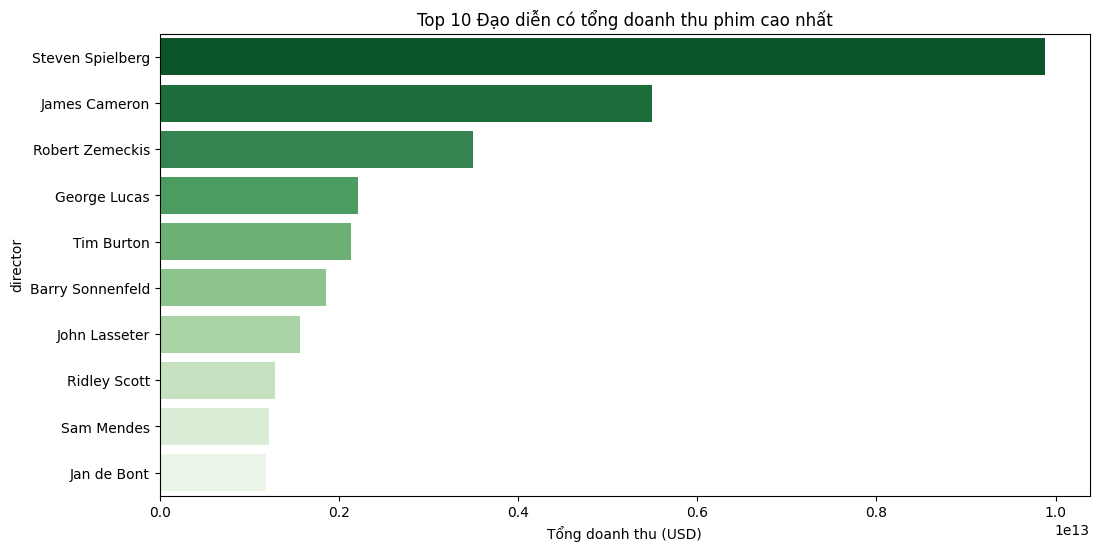

In [221]:
# Gom nhóm theo Đạo diễn và tính tổng doanh thu
# Chỉ lấy những dòng có revenue (tự động bỏ NaN)
director_revenue = full_data.groupby('director')['revenue'].sum().sort_values(ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(x=director_revenue.values, y=director_revenue.index, palette='Greens_r')
plt.title('Top 10 Đạo diễn có tổng doanh thu phim cao nhất')
plt.xlabel('Tổng doanh thu (USD)')
plt.show()

Biểu đồ trên thể hiện Top 10 đạo diễn có tổng doanh thu phim cao nhất, cho thấy sự chênh lệch rất lớn về mức độ thành công thương mại giữa các đạo diễn.

Nổi bật nhất là Steven Spielberg, với tổng doanh thu vượt mức 10 tỷ USD – cao gần gấp đôi so với người đứng thứ hai. Điều này phản ánh sức ảnh hưởng lâu dài của ông trong ngành điện ảnh, cùng hàng loạt tác phẩm bom tấn có tầm vóc lịch sử. Đứng phía sau là James Cameron với khoảng hơn 5 tỷ USD doanh thu, nổi bật với các phim kỷ lục như Avatar và Titanic. Vị trí thứ ba thuộc về Robert Zemeckis với doanh thu khoảng 3,5 tỷ USD, chứng minh sự bền bỉ trong phong cách làm phim nổi tiếng qua Forrest Gump hay Back to the Future.

Các vị trí tiếp theo như George Lucas, Tim Burton, Barry Sonnenfeld và John Lasseter đều nằm trong khoảng 1,5–2 tỷ USD. Họ có sự đóng góp lớn, nhưng quy mô doanh thu không cao bằng nhóm đầu bảng. Các đạo diễn Ridley Scott, Sam Mendes và Jan de Bont tuy vẫn đạt mức hơn 1 tỷ USD, song sự chênh lệch so với Spielberg cho thấy sự phân hóa rõ rệt về mức độ thành công phòng vé.

Nhìn chung, biểu đồ thể hiện tính phân tầng mạnh: chỉ một số ít đạo diễn đạt mức doanh thu vượt trội trong khi đa phần dừng lại ở ngưỡng trung bình khá. Các đạo diễn đứng đầu là những người tạo ra các thương hiệu phim lớn, có lượng khán giả trung thành và khả năng thành công toàn cầu. Điều này thể hiện mức độ ảnh hưởng của họ đối với thị trường điện ảnh thế giới.

#### Phân tích biến mục tiêu Rating 
1. Phân tích đơn biến

C:\Users\biedu\AppData\Local\Temp\ipykernel_19356\3695781708.py:7: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




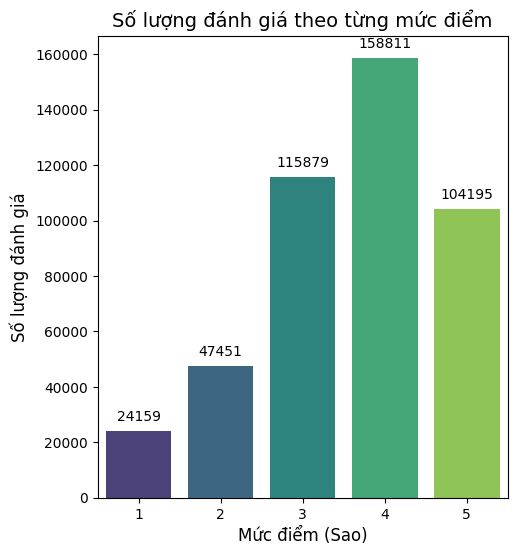

In [222]:
# Thiết lập kích thước tổng thể
plt.figure(figsize=(18, 6))

# --- BIỂU ĐỒ 1: PHÂN PHỐI SỐ LƯỢNG (COUNT PLOT) ---
# Giúp bạn thấy rõ số lượng đánh giá cho từng mức điểm (1-5 sao)
plt.subplot(1, 3, 1)
ax = sns.countplot(x='Rating', data=full_data, palette='viridis')
plt.title('Số lượng đánh giá theo từng mức điểm', fontsize=14)
plt.xlabel('Mức điểm (Sao)', fontsize=12)
plt.ylabel('Số lượng đánh giá', fontsize=12)

# Thêm số liệu cụ thể lên đầu cột để dễ đọc
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

Text(0.5, 1.0, 'Tỷ lệ phần trăm các mức điểm')

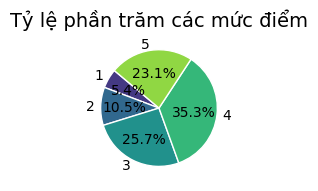

In [223]:
# --- BIỂU ĐỒ 2: TỶ TRỌNG PHẦN TRĂM (PIE CHART) ---
# Giúp hình dung cơ cấu thị hiếu người dùng
plt.subplot(1, 3, 2)
rating_counts = full_data['Rating'].value_counts().sort_index()
plt.pie(rating_counts, labels=rating_counts.index, autopct='%1.1f%%', startangle=140, 
    colors=sns.color_palette('viridis', 5), wedgeprops={'edgecolor': 'white'})
plt.title('Tỷ lệ phần trăm các mức điểm', fontsize=14)

In [224]:
fig = px.histogram(full_data,x='Rating', 
                   labels={'Rating': 'Điểm số', 'count': 'Số lượng'},
                   title="Biểu đồ phân phối điểm số")
fig.update_yaxes(title="Số lượng")
fig.update_traces(
    hovertemplate="Điểm số = %{x}<br>Số lượng = %{y}"
)
fig.show()

Dựa trên biểu đồ phân phối số lượng đánh giá theo từng mức điểm, có thể nhận định rằng dữ liệu mang tính lệch trái rõ rệt, khi phần lớn người dùng tập trung chấm điểm cao. Cụ thể, mức điểm 4 sao xuất hiện nhiều nhất, chiếm hơn 150 nghìn lượt đánh giá, tiếp theo là 5 sao với hơn 100 nghìn lượt. Trong khi đó, các mức điểm thấp (1–2 sao) xuất hiện rất ít. Điều này cho thấy xu hướng đánh giá tích cực là chủ đạo.

Kết quả này phản ánh đúng tâm lý người dùng trong hệ thống đánh giá phim: họ có xu hướng xem những bộ phim phù hợp với sở thích nên thường cho điểm cao. Ngược lại, các bộ phim dở hoặc không phù hợp thường bị bỏ dở, dẫn đến việc người xem không đánh giá hoặc không chấm quá thấp. Vì vậy, điểm 3 sao không thực sự đại diện mức trung bình, mà mang ý nghĩa thiên về mức "trung bình thấp". Một bộ phim muốn được xem là “hay” cần đạt mức 4–5 sao.

In [225]:
# --- IN RA CON SỐ THỐNG KÊ CỤ THỂ ---
mean_rating = full_data['Rating'].mean()
median_rating = full_data['Rating'].median()
print(f"Điểm đánh giá trung bình (Mean): {mean_rating:.2f}")
print(f"Điểm đánh giá trung vị (Median): {median_rating}")

Điểm đánh giá trung bình (Mean): 3.60
Điểm đánh giá trung vị (Median): 4.0


Hai giá trị Mean = 3.60 và Median = 4.0 cho thấy người dùng có xu hướng chấm điểm khá cao cho các bộ phim. Việc trung vị (4.0) lớn hơn trung bình (3.60) chứng tỏ phần lớn đánh giá tập trung ở mức tốt (4–5 sao), trong khi một số ít đánh giá thấp đã kéo trung bình giảm xuống. Trong trường hợp này, Median = 4.0 là giá trị đáng tin cậy hơn để đại diện cho mức độ hài lòng thực tế, vì nó phản ánh điểm điển hình mà phần lớn người dùng chấm, thay vì bị ảnh hưởng bởi một số ít đánh giá cực thấp. Do đó, khi đánh giá chất lượng phim của dataset, mức điểm phổ biến và đáng tin nhất chính là 4 sao.

2. Phân tích đa biến

Trả lời câu hỏi: "Phim càng nhiều người chấm điểm (càng nổi) thì điểm càng cao, hay phim "bom xịt" mới ít người chấm?" thông qua mối tương quan giữa "Độ nổi tiếng" và "Chất lượng"


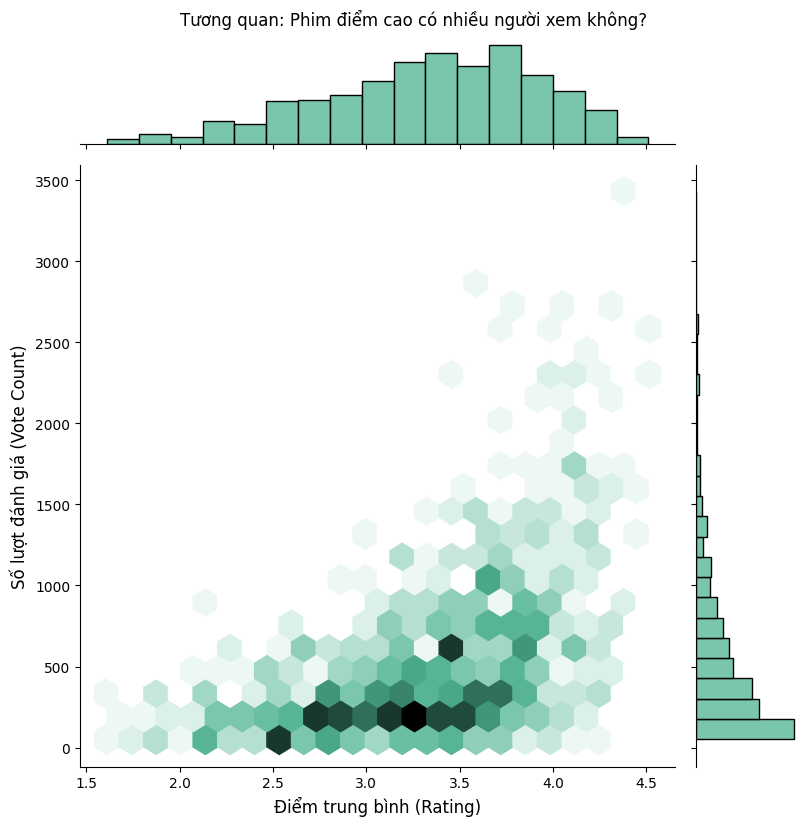

In [226]:
# Biểu đồ Joint Plot: Tương quan giữa "Độ nổi tiếng" và "Chất lượng"
# Tạo một biến đếm số lượng rating cho mỗi phim (Vote Count)
movie_stats = full_data.groupby('Title').agg({'Rating': ['mean', 'count']})
movie_stats.columns = ['avg_rating', 'vote_count']

# Lọc bớt các phim quá ít rating (< 50) để biểu đồ đỡ nhiễu
popular_movies = movie_stats[movie_stats['vote_count'] > 50]

# Vẽ Jointplot kiểu 'hex' (tổ ong) nhìn rất ngầu
# kind='hex' giúp nhìn rõ mật độ tập trung hơn là scatter chấm bi thông thường
g = sns.jointplot(x='avg_rating', y='vote_count', data=popular_movies, 
                  kind='hex', color='#4CB391', height=8)

g.fig.suptitle('Tương quan: Phim điểm cao có nhiều người xem không?', y=1.02)
g.set_axis_labels('Điểm trung bình (Rating)', 'Số lượt đánh giá (Vote Count)', fontsize=12)
plt.show()

Biểu đồ Jointplot (dạng tổ ong) cung cấp một góc nhìn sâu sắc về quy luật đào thải của điện ảnh. Phần lớn các điểm dữ liệu tập trung ở vùng điểm trung bình (3.0 - 3.5) với số lượng đánh giá thấp, phản ánh thực tế rằng đa số các bộ phim đều ở mức thường thường bậc trung và ít được chú ý. Tuy nhiên, khi quan sát các bộ phim có lượng tương tác "khủng" (trên 2000 lượt đánh giá), chúng ta thấy chúng hầu hết đều nằm ở vùng điểm số cao (trên 3.5). Hiện tượng này khẳng định mối tương quan thuận chiều giữa chất lượng và độ nổi tiếng: phim dở thường bị lãng quên nhanh chóng, trong khi chỉ những tác phẩm thực sự chất lượng mới đủ sức tạo ra hiệu ứng đám đông và thu hút lượng người xem lớn.

Trả lời câu hỏi: Đàn ông và Phụ nữ, ai "khắt khe" hơn khi chấm điểm? Boxplot bình thường không cho thấy mật độ, nhưng Violin plot thì có.

C:\Users\biedu\AppData\Local\Temp\ipykernel_19356\4243481608.py:7: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




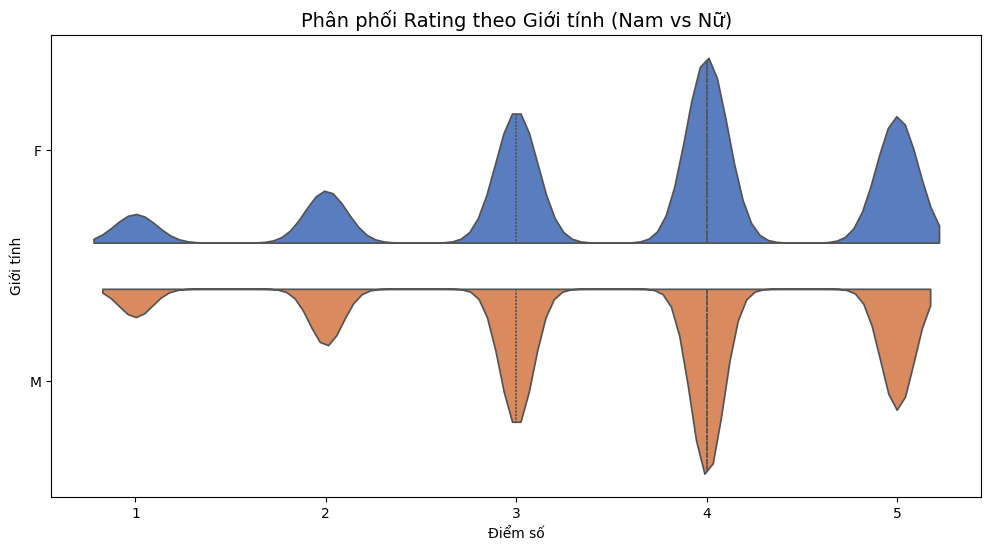

In [227]:
# Biểu đồ Violin Plot: So sánh Rating theo Giới tính/Độ tuổi
full_data = pd.merge(full_data, users[['UserID', 'Gender', 'Age']], on='UserID', how='left')
plt.figure(figsize=(12, 6))

# Vẽ Violin plot
# split=True: Chia đôi cây đàn, một nửa là Nam (M), một nửa là Nữ (F) để dễ so sánh
sns.violinplot(x='Rating', y='Gender', data=full_data, 
               palette='muted', split=True, inner='quartile')

plt.title('Phân phối Rating theo Giới tính (Nam vs Nữ)', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Giới tính')
plt.show()

Về xu hướng phân phối điểm đánh giá chung Biểu đồ cột và biểu đồ hộp (Box Plot) cùng chỉ ra một đặc điểm tâm lý rõ rệt của cộng đồng MovieLens: "Thiên kiến tích cực" (Positivity Bias). Phân phối dữ liệu có dạng lệch trái, với mật độ tập trung cao nhất ở mức 4 sao (gần 160.000 lượt) và mức trung vị cũng nằm tại con số 4. Điều này cho thấy người dùng có xu hướng chọn lọc phim kỹ lưỡng trước khi xem và thường hào phóng chấm điểm cho những tác phẩm họ yêu thích. Ngược lại, các mức điểm tiêu cực (1-2 sao) chiếm tỷ trọng rất nhỏ, phản ánh hành vi người dùng thường bỏ qua việc đánh giá những bộ phim kém chất lượng thay vì kiên nhẫn xem hết để chấm điểm thấp.

Về sự khác biệt hành vi giữa các nhóm giới tính Biểu đồ Violin (Violin Plot) cung cấp cái nhìn so sánh thú vị giữa người dùng Nam và Nữ. Mặc dù hình dáng phân phối tổng thể khá tương đồng (đều phình to ở mức 3-4 sao), nhưng có những sự khác biệt tinh tế. Nhóm người dùng Nữ thể hiện sự quyết đoán và hào phóng hơn, biểu hiện qua phần đỉnh nhọn và phình to hơn ở mức 4-5 sao. Trong khi đó, nhóm Nam giới có phổ đánh giá trải rộng hơn một chút xuống các mức điểm thấp (2-3 sao). Tuy nhiên, kết luận chung là giới tính không phải yếu tố gây phân cực sâu sắc về điểm số; cả hai giới đều chia sẻ chung một gu thẩm mỹ "dễ chịu" đối với các bộ phim họ chọn xem.

Về mối tương quan giữa chất lượng và độ nổi tiếng Biểu đồ tổ ong (Joint Plot) đã minh họa rõ nét quy luật đào thải khắc nghiệt của điện ảnh. Phần lớn các điểm dữ liệu tập trung ở vùng điểm trung bình (2.5 - 3.5) với số lượng đánh giá thấp, cho thấy đa số phim đều chìm vào quên lãng. Tuy nhiên, một xu hướng rất rõ ràng xuất hiện ở nhóm các bộ phim "bom tấn" (có trên 2000 lượt đánh giá): chúng hầu hết đều nằm lệch về phía điểm số cao (trên 3.5). Điều này khẳng định rằng để đạt được độ lan tỏa lớn và trở thành hiện tượng, một bộ phim bắt buộc phải có chất lượng nội dung tốt. Không có trường hợp ngoại lệ nào mà một bộ phim dở tệ lại có thể thu hút lượng tương tác khổng lồ trong tập dữ liệu này.

Trả lời câu hỏi: Thể loại phim nào được ưu ái nhất?

C:\Users\biedu\AppData\Local\Temp\ipykernel_19356\714296337.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




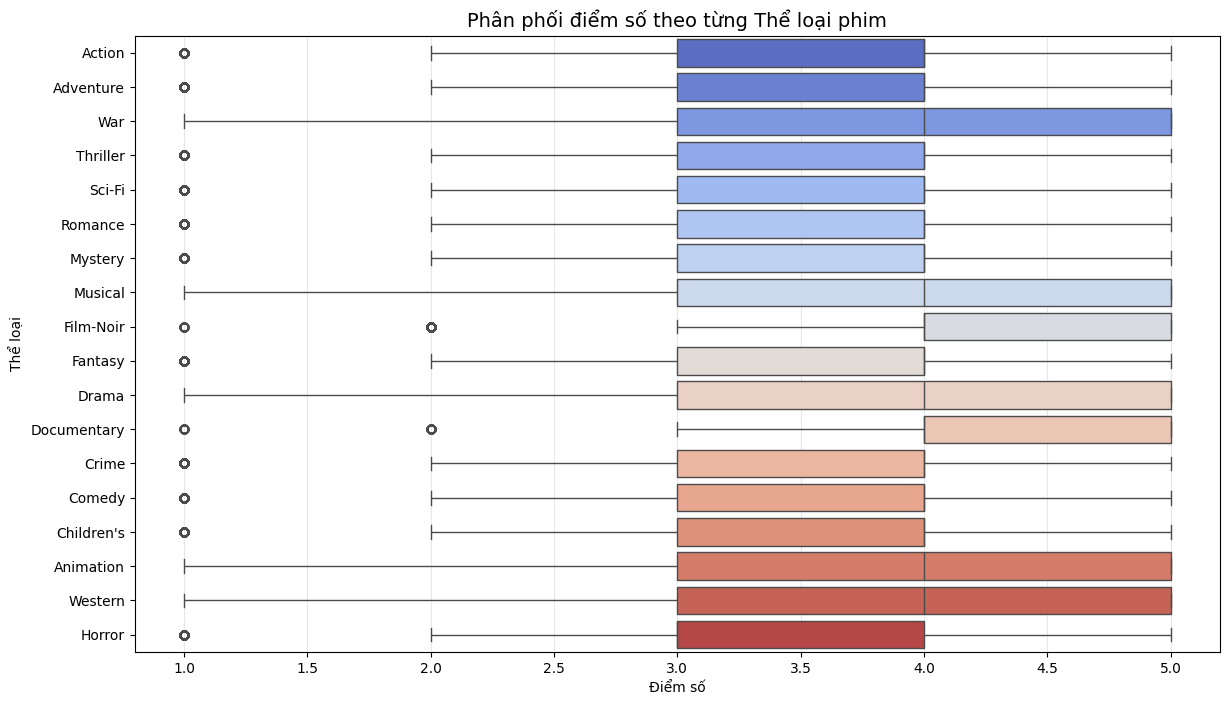

In [228]:
# Biểu đồ Heatmap: Ma trận Thể loại vs. Rating
# 1. Tách thể loại (Explode Genres) - Bước này hơi nặng chút
# Tạo bản sao để không ảnh hưởng dữ liệu gốc
genres_df = full_data[['MovieID', 'Rating', 'Genres']].copy()
# Chuyển chuỗi "Action|Comedy" thành list ["Action", "Comedy"]
genres_df['Genres'] = genres_df['Genres'].str.split('|')
# Bung nén (Explode): Biến 1 dòng chứa list thành nhiều dòng
genres_exploded = genres_df.explode('Genres')

# 2. Vẽ Boxplot sắp xếp theo điểm trung vị
plt.figure(figsize=(14, 8))

# Tính thứ tự sắp xếp: Thể loại nào có điểm trung vị cao nhất xếp trước
order = genres_exploded.groupby('Genres')['Rating'].median().sort_values(ascending=False).index

sns.boxplot(x='Rating', y='Genres', data=genres_exploded, 
            order=order, palette='coolwarm')

plt.title('Phân phối điểm số theo từng Thể loại phim', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Thể loại')
plt.grid(axis='x', alpha=0.3)
plt.show()

Phân tích hành vi và tâm lý đánh giá của người dùng Thông qua biểu đồ phân phối điểm số, chúng ta nhận thấy một đặc điểm tâm lý rõ rệt của cộng đồng MovieLens là "Thiên kiến tích cực" (Positivity Bias). Biểu đồ có dạng lệch trái với mật độ tập trung cao nhất ở mức 4 sao (Mode) và mức trung vị (Median) cũng nằm tại con số 4. Điều này chỉ ra rằng người dùng có xu hướng chọn lọc phim kỹ lưỡng trước khi xem và thường hào phóng chấm điểm cho những tác phẩm họ yêu thích. Ngược lại, các đánh giá tiêu cực (1-2 sao) chiếm tỷ trọng rất nhỏ, cho thấy người dùng thường bỏ qua việc đánh giá những bộ phim kém chất lượng thay vì kiên nhẫn xem hết để chấm điểm thấp.

Sự tương đồng và khác biệt trong thị hiếu theo giới tính Biểu đồ Violin (Violin Plot) cung cấp cái nhìn sâu sắc về sự tương quan giữa giới tính và điểm đánh giá. Kết quả cho thấy không có sự phân cực sâu sắc giữa hai giới; cả Nam và Nữ đều chia sẻ xu hướng đánh giá khá tương đồng với hình dáng phân phối phình to ở mức 3-4 sao. Tuy nhiên, nhóm người dùng Nữ thể hiện sự "quyết đoán" hơn một chút, biểu hiện qua phần đỉnh nhọn và tập trung cao độ ở các mức điểm chẵn (4 và 5 sao). Trong khi đó, nhóm Nam giới có phổ đánh giá trải rộng hơn xuống các mức điểm thấp, cho thấy sự khắt khe hoặc đa dạng hơn đôi chút trong gu thưởng thức, nhưng nhìn chung sự khác biệt này không đáng kể.

Quy luật đào thải và mối quan hệ giữa Chất lượng - Độ phổ biến Biểu đồ tổ ong (Joint Plot) đã minh họa rõ nét quy luật khắc nghiệt của thị trường điện ảnh. Phần lớn các bộ phim trong dữ liệu đều tập trung ở vùng điểm trung bình (2.5 - 3.5) với số lượng người đánh giá thấp, phản ánh thực tế là đa số phim đều chìm vào quên lãng. Đáng chú ý, một xu hướng nhất quán xuất hiện ở nhóm các bộ phim "bom tấn" (có lượng tương tác khủng): chúng hầu hết đều nằm lệch về phía điểm số cao (trên 3.5). Điều này khẳng định mối tương quan thuận chiều chặt chẽ: để đạt được độ lan tỏa lớn (Viral), một bộ phim bắt buộc phải có chất lượng nội dung tốt. Không có trường hợp ngoại lệ nào mà một bộ phim dở tệ lại có thể duy trì được lượng người xem khổng lồ trong tập dữ liệu này.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

### 1. Yếu tố Tài chính
Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

## Kết luận và Trực quan hóa